# CivicFlux — Sustainability and Resource Optimization

**Notebook 08 · NetworkX topology review + OR-Tools resource allocation**

A reproducible decision-support experiment. BattLeDIM supplies one documented L-TOWN water graph, but the workspace has no municipal incident inventory, crew roster, intervention cost database, or resource optimizer. We reuse the existing graph parsers and represent resource decisions with a small pure CP-SAT component. The optimization inputs are explicitly synthetic; no recommendation is dispatched or approved automatically.

## 01. Research question and decision boundary

Given a finite set of hypothetical intervention proposals and a finite resource inventory, select a feasible set maximizing transparent weighted utility. This is a constrained selection model, not an ML model. It does not estimate the causal impact of interventions and does not define operational safety policy.

Compare OR-Tools CP-SAT with severity-first and utility-greedy baselines subject to the same budget, crew-hour and pump constraints. Test resource scarcity, conflicting priorities and weight sensitivity. Recommendations require human review.

### 1.1 Reproducible setup

Use shared CivicFlux graph readers and the reusable versioned CP-SAT component. Every seed and score weight is saved.

In [1]:
from pathlib import Path
import sys,json,time,platform,importlib.metadata
import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from IPython.display import display
ROOT=Path.cwd() if (Path.cwd()/'civicflux_core.py').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from src.civicflux.graph import read_epanet,synthetic_graph,graph_fingerprint,NODE_TYPES
from src.civicflux.optimization import (DEFAULT_WEIGHTS,VERSION,validate_weights,score_intervention,
 solve_cpsat,greedy_allocate,assert_feasible)
from civicflux_core import sha256
sns.set_theme(style='whitegrid');SEED=42
OUT=ROOT/'artifacts'/'resource_optimization'/'v1.1.0';OUT.mkdir(parents=True,exist_ok=True)
print('Python',platform.python_version(),'NetworkX',importlib.metadata.version('networkx'),'OR-Tools',importlib.metadata.version('ortools'))

Python 3.13.5 NetworkX 3.7 OR-Tools 9.14.6206


### 1.2 Existing optimizer and approval-path audit

Repository inspection found no existing CivicFlux infrastructure optimizer, intervention database, or approval API. Nearby demo apps belong to unrelated domains. The new helper returns a plan and flags approval required; it has no dispatch or network capability.

In [2]:
print('Optimization interface: src/civicflux/optimization.py')
print('Graph interface: src/civicflux/graph.py')
print('No verified civic crew/resource inventory or approval schema was found.')

Optimization interface: src/civicflux/optimization.py
Graph interface: src/civicflux/graph.py
No verified civic crew/resource inventory or approval schema was found.


## 02. Infrastructure graph and evidence

The L-TOWN EPANET file provides nominal hydraulic node/link topology for a benchmark network. It is not municipal Delhi data or a verified cross-sector drainage/road/pump/facility map. First visualize its real benchmark topology and derive centrality, keeping all dependency interpretation cautious. Then use the existing versioned `synthetic_graph` generator for the hypothetical multi-sector dependency example; its edge weights mean simulated service-dependency strength.

### 2.1 Read and fingerprint supplied L-TOWN network

Node IDs and pipe lengths come from the checked source file. Their geographic coordinates are benchmark plotting coordinates, not a CivicFlux geographic join.

In [3]:
water_path=ROOT/'data/raw/battledim/L-TOWN.inp'
water_graph=read_epanet(water_path)
water_fp=graph_fingerprint(water_graph)
print('L-TOWN nominal graph',water_graph.number_of_nodes(),'nodes',water_graph.number_of_edges(),'links')
print('Synthetic flag because the benchmark scenario/network is simulated:',water_graph.graph['synthetic'])
print('SHA256',sha256(water_path),'fingerprint',water_fp)

L-TOWN nominal graph 785 nodes 909 links
Synthetic flag because the benchmark scenario/network is simulated: True
SHA256 a7551b86745f4cc3433c78e60023077fa1386947d4d35372ffd3a0405622b436 fingerprint 61c70269f53e3fbba8f8a7029f68f2f9b86e0b32bf8bf90ce437c3b2dff2b39a


### 2.2 Topology EDA

Connectivity and degree can help identify high-connectivity benchmark elements, but are not measured civic criticality.

Connected components 1 largest 785


count    785.000000
mean       2.315924
std        0.628461
min        1.000000
25%        2.000000
50%        2.000000
75%        3.000000
max        5.000000
Name: degree, dtype: float64

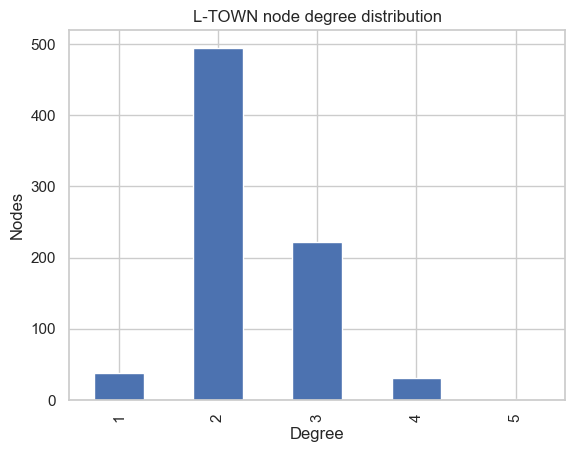

In [4]:
components=list(__import__('networkx').connected_components(water_graph))
print('Connected components',len(components),'largest',max(map(len,components)))
degree=pd.Series(dict(water_graph.degree()),name='degree')
display(degree.describe())
degree.value_counts().sort_index().plot.bar(title='L-TOWN node degree distribution',xlabel='Degree',ylabel='Nodes');plt.show()

### 2.3 Visualize BattLeDIM L-TOWN reference topology

Use the supplied layout coordinates, pressure sensor placements and typed pipe/pump/reservoir nodes.

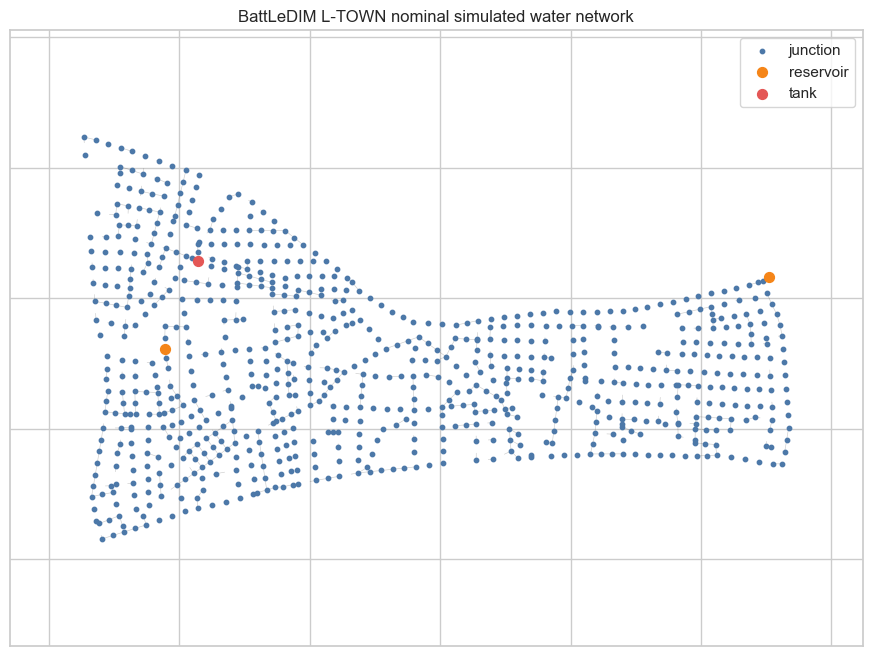

In [5]:
import networkx as nx
pos=nx.get_node_attributes(water_graph,'pos')
fig,ax=plt.subplots(figsize=(11,8))
nx.draw_networkx_edges(water_graph,pos,ax=ax,alpha=.22,width=.45)
colors={'junction':'#4c78a8','reservoir':'#f58518','tank':'#e45756'}
for kind,color in colors.items():
    nodes=[n for n,d in water_graph.nodes(data=True) if d.get('node_type')==kind]
    nx.draw_networkx_nodes(water_graph,pos,nodelist=nodes,node_color=color,node_size=10 if kind=='junction' else 50,ax=ax,label=kind)
ax.legend();ax.set_title('BattLeDIM L-TOWN nominal simulated water network');ax.axis('equal');plt.show()

### 2.4 NetworkX centrality

Betweenness centrality is computed on the actual undirected hydraulic adjacency. It does not prove outage probability or system importance.

,node,betweenness,degree
218,n219,0.387781,3
221,n222,0.320800,3
337,n338,0.319321,4
630,n631,0.315346,2
629,n630,0.292999,2
61,n62,0.283033,4
92,n93,0.260044,3
220,n221,0.259621,3
341,n342,0.256119,3
465,n466,0.255200,2


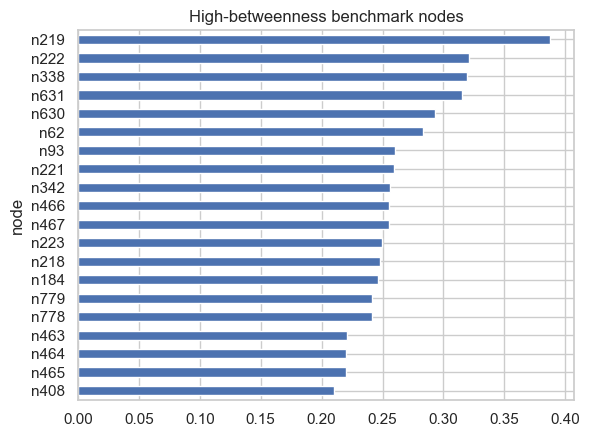

In [6]:
bet=nx.betweenness_centrality(water_graph,weight='length',normalized=True)
centrality=pd.DataFrame({'node':list(bet),'betweenness':list(bet.values()),'degree':[water_graph.degree(n) for n in bet]})
display(centrality.nlargest(12,'betweenness'))
centrality.nlargest(20,'betweenness').sort_values('betweenness').plot.barh(x='node',y='betweenness',legend=False,title='High-betweenness benchmark nodes');plt.show()

### 2.5 Explicitly hypothetical multi-sector service graph

Reuses the shared graph builder. Directed links mean service-provider node → dependent node. The topology is generated for illustration, not inferred from local geography.

In [7]:
graph=synthetic_graph(seed=SEED,n_per_type=8)
assert graph.graph['synthetic'] is True
print(graph.number_of_nodes(),'hypothetical nodes;',graph.number_of_edges(),'directed dependency edges')
print(pd.Series(nx.get_node_attributes(graph,'node_type')).value_counts())

40 hypothetical nodes; 96 directed dependency edges
drainage    8
road        8
water       8
pump        8
facility    8
Name: count, dtype: int64


### 2.6 Dependency weight and direction

Direction controls cascade interpretation. Weight is a declared synthetic probability-like service-dependency strength, not empirical failure transmission.

edges  mean_weight
provider_type dependent_type                    
drainage      road               16     0.580073
pump          drainage           16     0.487911
              water              16     0.551657
road          facility           16     0.506654
              pump               16     0.393495
water         facility           16     0.501868

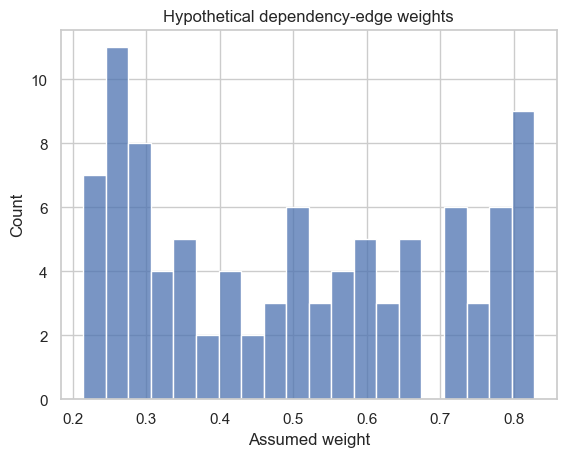

In [8]:
edge_data=pd.DataFrame([{'provider_type':graph.nodes[u]['node_type'],'dependent_type':graph.nodes[v]['node_type'],'weight':d['weight'],'delay_minutes':d['delay_minutes']} for u,v,d in graph.edges(data=True)])
display(edge_data.groupby(['provider_type','dependent_type']).agg(edges=('weight','size'),mean_weight=('weight','mean')))
sns.histplot(edge_data.weight,bins=20);plt.title('Hypothetical dependency-edge weights');plt.xlabel('Assumed weight');plt.show()

## 03. Scenario inventory and provenance

Create proposals from hypothetical nodes in the synthetic graph. Severity, expected service improvement, cascade reach, equity proxy, environmental benefit, carbon burden, crew skill, job duration, pump use and monetary cost are generated under fixed distributions below. **The equity value is a randomized placeholder, not demographic or service-access data.** Carbon and cost coefficients are scenario assumptions, not life-cycle accounting or procurement quotations.

### 3.1 Generate synthetic intervention candidates

Four conflict/scarcity scenarios share the same candidate cases so resource feasibility and objective comparisons are interpretable.

In [9]:
rng=np.random.default_rng(SEED)
node_list=list(graph.nodes(data=True))
node_importance=nx.betweenness_centrality(graph)
crew_map={'water':'water','pump':'water','drainage':'drain','road':'road','facility':'water'}
def make_cases(seed,n=30):
    r=np.random.default_rng(seed);rows=[]
    for i in range(n):
        node,d=node_list[i%len(node_list)]
        # A candidate is a plan under a synthetic scenario, not a real recommendation.
        rows.append({'case_id':f'S{seed}-C{i:02d}','node_id':node,'node_type':d['node_type'],
          'urgency':float(r.integers(1,6)/5),'cascade':float(min(1,node_importance[node]*50+r.uniform(.1,.6))),
          'service':float(r.uniform(.25,1)),'equity_proxy':float(r.uniform(0,1)),
          'environmental_benefit':float(r.uniform(0,1)),'carbon_penalty':float(r.uniform(0,1)),
          'crew_type':crew_map[d['node_type']],'duration_hours':float(r.integers(1,5)),
          'pumps_required':int(r.random()<.35),'cost':int(r.integers(3000,16000)),
          'budget_assumption_currency':'INR (hypothetical)','scenario_seed':seed,
          'resource_note':'Synthetic planning assumption; no measured crew or inventory data.'})
    return rows
cases=make_cases(SEED,32)
candidate_frame=pd.DataFrame(cases)
display(candidate_frame.head());display(candidate_frame.describe(include='all').T)
candidate_frame.to_csv(OUT/'scenario_candidates.csv',index=False)

,case_id,node_id,node_type,urgency,cascade,service,equity_proxy,environmental_benefit,carbon_penalty,crew_type,duration_hours,pumps_required,cost,budget_assumption_currency,scenario_seed,resource_note
0,S42-C00,drainage_0,drainage,0.2,1.000000,0.893948,0.697368,0.094177,0.975622,drain,4.0,0,12327,INR (hypothetical),42,Synthetic planning assumption; no measured cre...
1,S42-C01,drainage_1,drainage,0.8,1.000000,0.587789,0.370798,0.926765,0.643865,drain,2.0,0,13695,INR (hypothetical),42,Synthetic planning assumption; no measured cre...
2,S42-C02,drainage_2,drainage,0.6,0.377292,0.297863,0.827631,0.631664,0.758088,drain,1.0,0,3882,INR (hypothetical),42,Synthetic planning assumption; no measured cre...
3,S42-C03,drainage_3,drainage,1.0,1.000000,0.833788,0.194639,0.466721,0.043804,drain,3.0,0,5005,INR (hypothetical),42,Synthetic planning assumption; no measured cre...
4,S42-C04,drainage_4,drainage,1.0,1.000000,0.494369,0.370460,0.469556,0.189471,drain,3.0,1,11924,INR (hypothetical),42,Synthetic planning assumption; no measured cre...


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
case_id,32,32,S42-C00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
node_id,32,32,drainage_0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
node_type,32,4,drainage,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
urgency,32.0,NaN,NaN,NaN,0.6375,0.306647,0.2,0.4,0.6,1.0,1.0
cascade,32.0,NaN,NaN,NaN,0.912309,0.207877,0.183486,1.0,1.0,1.0,1.0
service,32.0,NaN,NaN,NaN,0.600367,0.211285,0.260452,0.435092,0.596453,0.758989,0.971423
equity_proxy,32.0,NaN,NaN,NaN,0.472273,0.280463,0.044911,0.225888,0.398414,0.768931,0.936813
environmental_benefit,32.0,NaN,NaN,NaN,0.508065,0.295966,0.041614,0.286377,0.468469,0.761893,0.952899
carbon_penalty,32.0,NaN,NaN,NaN,0.547465,0.249247,0.043804,0.414562,0.605672,0.705065,0.992376
crew_type,32,3,water,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3.2 Score construction and normalization

Factors are supplied on [0,1]; weighted sum preserves a transparent unitless utility. Carbon is a penalty (negative contribution); affordability is also enforced as a hard budget constraint.

In [10]:
weights=validate_weights(DEFAULT_WEIGHTS)
print('Normalized score weights',weights,'sum',sum(weights.values()))
candidate_frame['utility']=[score_intervention(c,weights) for c in cases]
display(candidate_frame[['case_id',*weights,'utility','cost']].sort_values('utility',ascending=False).head(12))

Normalized score weights {'urgency': 0.25, 'cascade': 0.2, 'service': 0.2, 'equity_proxy': 0.15, 'environmental_benefit': 0.15, 'carbon_penalty': 0.05} sum 1.0


,case_id,urgency,cascade,service,equity_proxy,environmental_benefit,carbon_penalty,utility,cost
31,S42-C31,1.0,1.000000,0.949767,0.804361,0.467382,0.784763,0.791477,3231
10,S42-C10,1.0,1.000000,0.746437,0.557032,0.783898,0.664314,0.767211,8433
28,S42-C28,1.0,1.000000,0.399832,0.804125,0.715407,0.738984,0.720947,8639
3,S42-C03,1.0,1.000000,0.833788,0.194639,0.466721,0.043804,0.713771,5005
7,S42-C07,0.8,1.000000,0.778874,0.780729,0.458916,0.568741,0.713284,4817
24,S42-C24,1.0,1.000000,0.639144,0.315929,0.772012,0.661661,0.707937,14521
30,S42-C30,1.0,1.000000,0.666399,0.633975,0.105897,0.140340,0.687244,3084
1,S42-C01,0.8,1.000000,0.587789,0.370798,0.926765,0.643865,0.679999,13695
13,S42-C13,0.2,1.000000,0.971423,0.908581,0.699707,0.265870,0.672234,15599
8,S42-C08,0.6,1.000000,0.673927,0.764999,0.634718,0.553579,0.667064,13333


### 3.3 Score-factor distributions and rank

No outcome data exists to validate these scores. Weight sensitivity asks how the hypothetical ranking changes under alternative declared priorities.

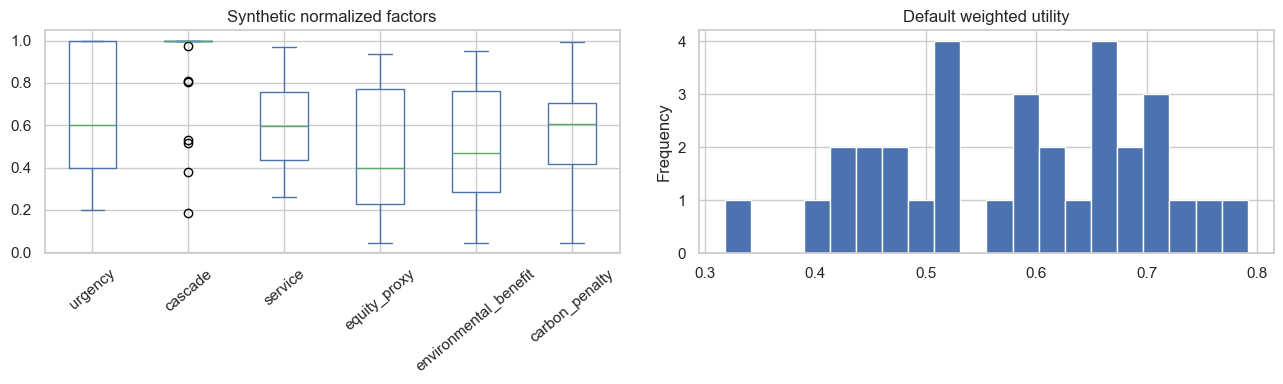

In [11]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
candidate_frame[list(weights)].plot.box(ax=ax[0],rot=40,title='Synthetic normalized factors')
candidate_frame.utility.plot.hist(bins=20,ax=ax[1],title='Default weighted utility');plt.tight_layout();plt.show()

## 04. Decision model

For candidate interventions i, choose binary xᵢ. Maximize Σᵢ uᵢxᵢ subject to: (a) each incident/case appears at most once; (b) total assumed cost ≤ scenario budget; (c) total pump units ≤ inventory; (d) assigned team hours ≤ available hours per skill. CP-SAT uses integer-scaled utilities and deterministic single-worker settings. An infeasible result is surfaced; there is no relax-and-dispatch fallback.

Severity-first and utility-greedy baselines apply the **same constraints** while walking a fixed ranking. The exact optimum can outperform these heuristics, but its selected set reflects only the synthetic scoring assumptions supplied here.

### 4.1 Resource scenarios

Normal, scarce budget, pump shortage and crew shortage are explicit hypothetical inventories.

In [12]:
scenarios={
 'normal':{'budget':150000,'pumps':8,'crew_hours':{'water':36,'drain':30,'road':24}},
 'budget_scarce':{'budget':55000,'pumps':8,'crew_hours':{'water':36,'drain':30,'road':24}},
 'pump_shortage':{'budget':100000,'pumps':2,'crew_hours':{'water':24,'drain':24,'road':24}},
 'crew_shortage':{'budget':100000,'pumps':5,'crew_hours':{'water':8,'drain':7,'road':6}}}
display(pd.DataFrame([{'scenario':k,'budget_INR_assumption':v['budget'],'pumps':v['pumps'],**{f'{c}_hours':h for c,h in v['crew_hours'].items()}} for k,v in scenarios.items()]))

,scenario,budget_INR_assumption,pumps,water_hours,drain_hours,road_hours
0,normal,150000,8,36,30,24
1,budget_scarce,55000,8,36,30,24
2,pump_shortage,100000,2,24,24,24
3,crew_shortage,100000,5,8,7,6


### 4.2 Solve and enforce feasibility

OR-Tools returns a recommended set and metrics. The output requires a human to review each choice.

In [13]:
methods={};timings=[]
for scenario_name,resource in scenarios.items():
    for method in ['severity_greedy','utility_greedy','CP-SAT']:
        start=time.perf_counter()
        result=(solve_cpsat(cases,resource,time_limit=3) if method=='CP-SAT' else greedy_allocate(cases,resource,method='severity' if method.startswith('severity') else 'utility'))
        elapsed=time.perf_counter()-start;assert_feasible(result['selected'],resource)
        methods[(scenario_name,method)]=result
        timings.append({'scenario':scenario_name,'method':method,'status':result['status'],'utility':result['objective'],
          'selected_count':len(result['selected']),'budget_used':result['used']['budget'],'pump_use':result['used']['pumps'],
          'solver_seconds':elapsed,'approval_required':result['approval_required'],'dispatch_allowed':result['dispatch_allowed']})
comparison=pd.DataFrame(timings);display(comparison)

,scenario,method,status,utility,selected_count,budget_used,pump_use,solver_seconds,approval_required,dispatch_allowed
0,normal,severity_greedy,HEURISTIC_FEASIBLE,11.225591,17,149353,6,0.000127,True,False
1,normal,utility_greedy,HEURISTIC_FEASIBLE,10.902363,16,146498,5,0.000096,True,False
2,normal,CP-SAT,OPTIMAL,12.418516,21,149215,8,0.020408,True,False
3,budget_scarce,severity_greedy,HEURISTIC_FEASIBLE,5.053989,7,54837,3,0.000102,True,False
4,budget_scarce,utility_greedy,HEURISTIC_FEASIBLE,5.752837,8,54790,3,0.000088,True,False
5,budget_scarce,CP-SAT,OPTIMAL,6.731123,11,54718,3,0.001971,True,False
6,pump_shortage,severity_greedy,HEURISTIC_FEASIBLE,8.028084,12,97216,2,0.000106,True,False
7,pump_shortage,utility_greedy,HEURISTIC_FEASIBLE,8.138415,12,99968,2,0.000096,True,False
8,pump_shortage,CP-SAT,OPTIMAL,9.225179,15,97549,2,0.002415,True,False
9,crew_shortage,severity_greedy,HEURISTIC_FEASIBLE,6.067082,9,72111,4,0.000103,True,False


### 4.3 Constraint satisfaction and utilization

Every method satisfies the same hard budget, pump and crew-hour constraints. Verify solver status and feasibility rather than assuming it.

In [14]:
assert all(assert_feasible(r['selected'],r['available']) for r in methods.values())
assert not any(r['dispatch_allowed'] for r in methods.values())
comparison['budget_utilization']=comparison.budget_used/comparison.scenario.map({k:v['budget'] for k,v in scenarios.items()})
comparison['incident_coverage']=comparison.selected_count/len(cases)
display(comparison.groupby('method').agg(mean_utility=('utility','mean'),mean_selected=('selected_count','mean'),mean_budget_use=('budget_utilization','mean'),mean_solver_seconds=('solver_seconds','mean')))
comparison.to_csv(OUT/'method_comparison.csv',index=False)

,mean_utility,mean_selected,mean_budget_use,mean_solver_seconds
method,,,,
CP-SAT,9.023625,14.75,0.984107,0.008194
severity_greedy,7.593687,11.25,0.921498,0.000110
utility_greedy,7.780458,11.25,0.933051,0.000093


### 4.4 Utility, coverage and resource-use plots

Solver runtime is machine-dependent. Utility, feasibility and use are measured on synthetic examples only.

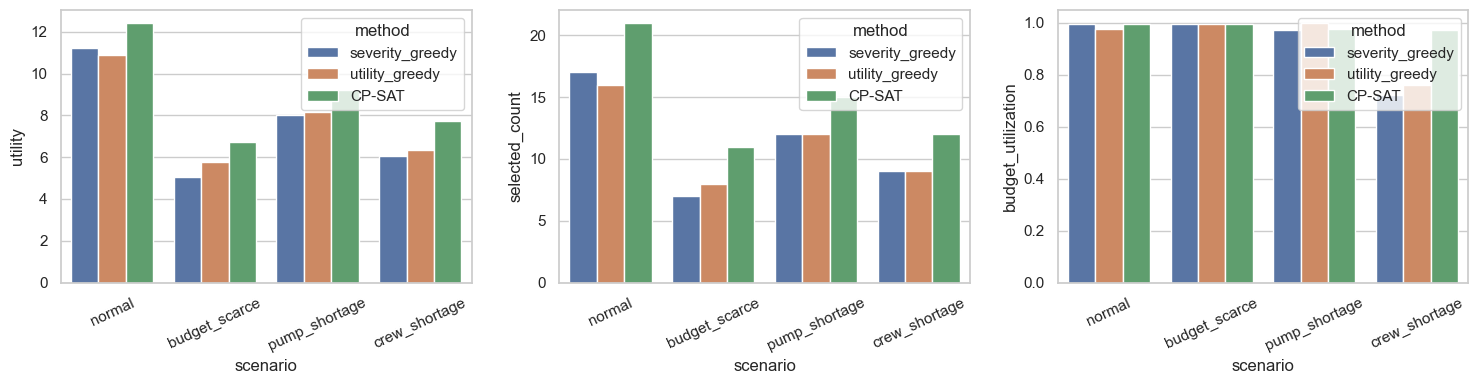

In [15]:
fig,ax=plt.subplots(1,3,figsize=(15,4))
sns.barplot(data=comparison,x='scenario',y='utility',hue='method',ax=ax[0]);ax[0].tick_params(axis='x',rotation=25)
sns.barplot(data=comparison,x='scenario',y='selected_count',hue='method',ax=ax[1]);ax[1].tick_params(axis='x',rotation=25)
sns.barplot(data=comparison,x='scenario',y='budget_utilization',hue='method',ax=ax[2]);ax[2].tick_params(axis='x',rotation=25)
plt.tight_layout();plt.show()

## 05. Weight sensitivity and robustness

Weights can change rankings. Do not tune them on synthetic solver output to imply a preferred real public policy. Run transparent perturbations and report selected-set stability, objective and affordability. Equity inputs are fictional until linked to a valid, privacy-reviewed service-access indicator; no demographic inference is made.

### 5.1 Sustainability and equity weighting

Raise each configured weight while renormalizing the remaining weight mass proportionally. Inventory constraints do not change.

In [16]:
weight_rows=[]
for focus in ['cascade','environmental_benefit','equity_proxy','carbon_penalty']:
    for target in [.05,.15,.30,.45]:
        w=dict(weights);rest=sum(v for k,v in w.items() if k!=focus)
        for k in w:
            w[k]=target if k==focus else (1-target)*w[k]/rest
        w=validate_weights(w);weighted=[{**c,'utility':score_intervention(c,w)} for c in cases]
        r=solve_cpsat(weighted,scenarios['normal'],weights=w,time_limit=3)
        weight_rows.append({'focus':focus,'weight':w[focus],'utility':r['objective'],'selected_count':len(r['selected']),
                            'selected_ids':tuple(sorted(c['case_id'] for c in r['selected'])),'weights':json.dumps(w,sort_keys=True)})
weight_sensitivity=pd.DataFrame(weight_rows);display(weight_sensitivity.drop(columns='weights'))
weight_sensitivity.to_csv(OUT/'weight_sensitivity.csv',index=False)

,focus,weight,utility,selected_count,selected_ids
0,cascade,0.05,11.381229,20,"(S42-C01, S42-C02, S42-C03, S42-C04, S42-C05, ..."
1,cascade,0.15,12.064140,20,"(S42-C01, S42-C02, S42-C03, S42-C04, S42-C05, ..."
2,cascade,0.30,13.224812,21,"(S42-C00, S42-C02, S42-C03, S42-C04, S42-C05, ..."
3,cascade,0.45,14.434256,21,"(S42-C00, S42-C02, S42-C03, S42-C04, S42-C05, ..."
4,environmental_benefit,0.05,12.632665,21,"(S42-C02, S42-C03, S42-C04, S42-C05, S42-C07, ..."
5,environmental_benefit,0.15,12.418516,21,"(S42-C00, S42-C02, S42-C03, S42-C04, S42-C05, ..."
6,environmental_benefit,0.30,12.231295,20,"(S42-C01, S42-C02, S42-C03, S42-C04, S42-C05, ..."
7,environmental_benefit,0.45,12.175039,20,"(S42-C01, S42-C02, S42-C03, S42-C05, S42-C07, ..."
8,equity_proxy,0.05,12.776155,20,"(S42-C01, S42-C02, S42-C03, S42-C04, S42-C05, ..."
9,equity_proxy,0.15,12.418516,21,"(S42-C00, S42-C02, S42-C03, S42-C04, S42-C05, ..."


### 5.2 Selected-set stability

Jaccard overlap reveals whether the top-level selection depends strongly on one subjective score factor.

,focus,weight,jaccard_vs_default
0,cascade,0.05,0.708333
1,cascade,0.15,0.708333
2,cascade,0.30,1.000000
3,cascade,0.45,1.000000
4,environmental_benefit,0.05,0.826087
5,environmental_benefit,0.15,1.000000
6,environmental_benefit,0.30,0.782609
7,environmental_benefit,0.45,0.708333
8,equity_proxy,0.05,0.708333
9,equity_proxy,0.15,1.000000


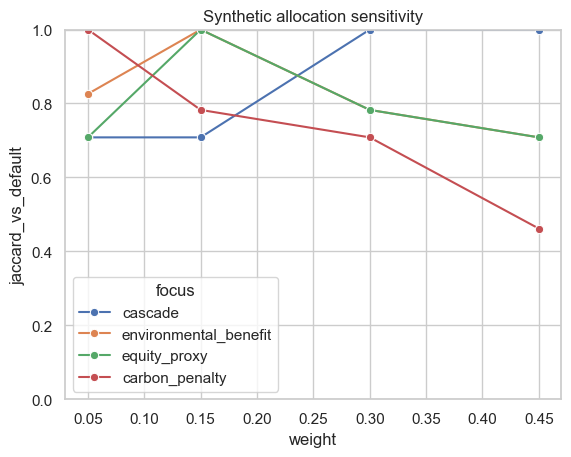

In [17]:
reference=set(methods[('normal','CP-SAT')]['selected'][i]['case_id'] for i in range(len(methods[('normal','CP-SAT')]['selected'])))
stability=[]
for row in weight_sensitivity.itertuples():
    selected=set(row.selected_ids);stability.append({'focus':row.focus,'weight':row.weight,'jaccard_vs_default':len(reference&selected)/max(1,len(reference|selected))})
stability=pd.DataFrame(stability);display(stability)
sns.lineplot(data=stability,x='weight',y='jaccard_vs_default',hue='focus',marker='o');plt.ylim(0,1);plt.title('Synthetic allocation sensitivity');plt.show()

### 5.3 Random scenario stress test

Repeated random cases test implementation stability across different hypothetical inputs. They do not estimate real city-wide solver performance.

,mean_utility,std_utility,mean_selected
method,,,
CP-SAT,6.117014,0.919319,9.9
severity,4.294914,0.499822,6.1
utility,4.269993,0.807449,5.8


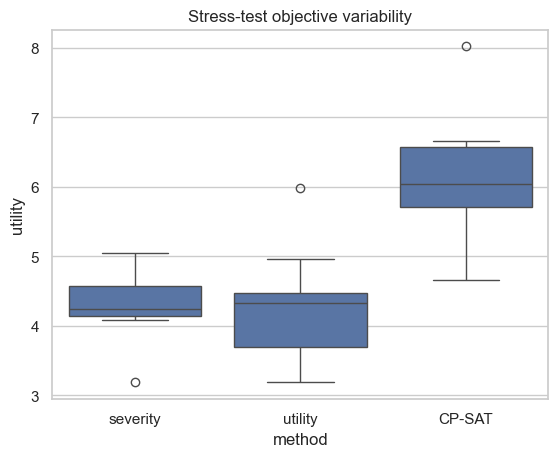

In [18]:
stress=[]
for seed in range(10,20):
    sample=make_cases(seed,32)
    resource=scenarios['budget_scarce']
    for method in ['severity','utility','CP-SAT']:
        result=solve_cpsat(sample,resource,time_limit=2) if method=='CP-SAT' else greedy_allocate(sample,resource,method=method)
        assert_feasible(result['selected'],resource)
        stress.append({'seed':seed,'method':method,'utility':result['objective'],'selected':len(result['selected']),'cost':result['used']['budget']})
stress=pd.DataFrame(stress);display(stress.groupby('method').agg(mean_utility=('utility','mean'),std_utility=('utility','std'),mean_selected=('selected','mean')))
sns.boxplot(data=stress,x='method',y='utility');plt.title('Stress-test objective variability');plt.show()
stress.to_csv(OUT/'scenario_stress.csv',index=False)

## 06. Explainability, integration and export

Export the normalized weights, graph fingerprint, assumptions, scenario cases, feasible selections and solver metrics as versioned JSON/CSV. Recommendations carry scenario provenance and human-approval flags. The workspace contains no reusable CivicFlux OR-Tools optimizer or approval API, so this is a pure research interface; it does not change a backend route.

### 6.1 Explain each recommended intervention

Expose factor contributions, cost and resource consumption. The score is a ranking aid, not an authorization.

In [19]:
selected=methods[('normal','CP-SAT')]['selected'];contrib=[]
for case in selected:
    vals={k:case[k] for k in weights};vals['carbon_penalty']=-vals['carbon_penalty']
    contrib.append({'case_id':case['case_id'],'node_id':case['node_id'],'node_type':case['node_type'],'utility':case['utility'],
       'cost_assumption':case['cost'],'crew_type':case['crew_type'],'hours':case['duration_hours'],'pumps':case['pumps_required'],
       **{f'{k}_contribution':weights[k]*vals[k] for k in weights}})
explanation=pd.DataFrame(contrib);display(explanation)
explanation.to_csv(OUT/'selected_explanations.csv',index=False)

,case_id,node_id,node_type,utility,cost_assumption,crew_type,hours,pumps,urgency_contribution,cascade_contribution,service_contribution,equity_proxy_contribution,environmental_benefit_contribution,carbon_penalty_contribution
0,S42-C00,drainage_0,drainage,0.498740,12327,drain,4.0,0,0.05,0.200000,0.178790,0.104605,0.014127,-0.048781
1,S42-C02,drainage_2,drainage,0.466021,3882,drain,1.0,0,0.15,0.075458,0.059573,0.124145,0.094750,-0.037904
2,S42-C03,drainage_3,drainage,0.713771,5005,drain,3.0,0,0.25,0.200000,0.166758,0.029196,0.070008,-0.002190
3,S42-C04,drainage_4,drainage,0.665403,11924,drain,3.0,1,0.25,0.200000,0.098874,0.055569,0.070433,-0.009474
4,S42-C05,drainage_5,drainage,0.650966,7060,drain,1.0,0,0.15,0.195033,0.150472,0.065573,0.124902,-0.035013
5,S42-C07,drainage_7,drainage,0.713284,4817,drain,1.0,1,0.20,0.200000,0.155775,0.117109,0.068837,-0.028437
6,S42-C09,road_1,road,0.466304,6041,road,1.0,1,0.10,0.200000,0.115508,0.032188,0.061279,-0.042670
7,S42-C10,road_2,road,0.767211,8433,road,2.0,0,0.25,0.200000,0.149287,0.083555,0.117585,-0.033216
8,S42-C11,road_3,road,0.438871,5096,road,3.0,0,0.25,0.036697,0.053407,0.013507,0.108354,-0.023094
9,S42-C14,road_6,road,0.517896,12381,road,3.0,1,0.10,0.200000,0.090836,0.014459,0.135390,-0.022789


### 6.2 Save selected allocation artifacts

Artifacts include optimality/feasibility status, objective and hard limits.

In [20]:
comparison.to_csv(OUT/'metrics.csv',index=False)
all_results={scenario:{method:result for (s,method),result in methods.items() if s==scenario} for scenario in scenarios}
(OUT/'optimization_results.json').write_text(json.dumps(all_results,indent=2,default=str))
(OUT/'scenario_manifest.json').write_text(json.dumps({'version':VERSION,'seed':SEED,'graph_id':graph.graph['graph_id'],'graph_fingerprint':graph_fingerprint(graph),
  'weights':weights,'synthetic':True,'unit_cost':'hypothetical INR','inventory':'scenario-specific fictional availability',
  'human_approval_required':True,'dispatch_allowed':False},indent=2))

513

### 6.3 CivicFlux recommendation envelope

An application can pass this envelope to an existing human review queue after its schema is verified. Predictions alone cannot approve procurement or dispatch.

In [21]:
recommendations=[{'case_id':c['case_id'],'node_id':c['node_id'],'utility':c['utility'],'estimated_cost_assumption':c['cost'],
 'resources':{'crew_type':c['crew_type'],'hours':c['duration_hours'],'pumps':c['pumps_required']},
 'provenance':'synthetic scenario','requires_human_approval':True,'dispatch_allowed':False} for c in selected]
(OUT/'approval_envelope_example.json').write_text(json.dumps({'component':'resource_optimizer','version':VERSION,'scenario':'normal','recommendations':recommendations,'approval_status':'not_requested','automatic_dispatch':False},indent=2))
print(json.dumps({'selected':len(recommendations),'approval_required':True,'dispatch_allowed':False},indent=2))

{
  "selected": 21,
  "approval_required": true,
  "dispatch_allowed": false
}


### Findings and limitations

CP-SAT provides an optimal solution relative to the declared integer objective when status is `OPTIMAL`; baselines offer feasible comparison policies. A timeout may produce only `FEASIBLE`, and such status is retained. All numerical costs, crew capacities, carbon burdens, benefits and equity proxies are synthetic. The L-TOWN benchmark topology is water-only and is kept separate from the synthetic cross-sector service graph. No real affordability, environmental justice, procurement, crew safety or intervention-effect claim follows from this exercise. A CivicFlux deployment needs an operator-approved incident schema, live inventory, validated compatibility constraints, transparent policy weights, and an explicit approval workflow.

## Targeted review — common artifact and inference contract

The working scoring function and CP-SAT/greedy comparisons are retained. The shared interface validates scenario units, resources and provenance and always leaves approval pending. Outcome success scores are explicitly ineligible for allocation. We add essential metadata and schema so the consolidated registry can describe this optimization algorithm alongside ML artifacts without presenting the optimizer as a trained model.

In [22]:
from src.civicflux.contracts import standardize
(OUT/'feature_schema.json').write_text(json.dumps({'candidate_fields':list(candidate_frame.columns),'resources':['budget','pumps','crew_hours'],
 'units':{'cost':'hypothetical INR','duration_hours':'hours','crew_hours':'hours','pumps_required':'count'},'untrusted_success_estimate_policy':'rejected by shared serving interface'},indent=2))
standardize('resource_optimization',OUT,kind='OR-Tools CP-SAT + feasible greedy baselines',scope='synthetic intervention scenarios',
 units={'budget':'hypothetical INR','crew_hours':'hours','pumps':'count'},horizon='one simultaneous allocation window',provenance='documented fictional costs, resources and policy factors',
 supported_inputs={'cases':'finite factors in [0,1], integer costs/pump counts','resources':'nonnegative capacities'},validation='scenario feasibility verified; no real resource inventory')

{'contract_version': 'civicflux.research.v1',
 'component': 'resource_optimization',
 'artifact_version': 'v1.1.0',
 'component_kind': 'OR-Tools CP-SAT + feasible greedy baselines',
 'geographic_scope': 'synthetic intervention scenarios',
 'units': {'budget': 'hypothetical INR',
  'crew_hours': 'hours',
  'pumps': 'count'},
 'horizon': 'one simultaneous allocation window',
 'provenance': 'documented fictional costs, resources and policy factors',
 'supported_inputs': {'cases': 'finite factors in [0,1], integer costs/pump counts',
  'resources': 'nonnegative capacities'},
 'validation_status': 'scenario feasibility verified; no real resource inventory',
 'operational_supported': False,
 'research_only': True,
 'automatic_dispatch': False,
 'artifacts': {'approval_envelope_example.json': {'path': '/Users/jiyahooda/Documents/New project/civicflux_ml/artifacts/resource_optimization/v1.1.0/approval_envelope_example.json',
   'sha256': '9b2a84dde57967db280e26dc3124e357939e3b6c7cb0bfcc41b68e4